# Agrupación de casas de California

**Objetivo:** clasificar casas según la región en la que se encuentran y la renta media de su bloque censal.

Usamos el dataset **California Housing**, construido con el censo de California de 1990. Cada fila es un *grupo de bloques censales*, la unidad geográfica más pequeña con datos publicados. De las nueve columnas originales solo usamos tres:

- `Latitude` y `Longitude`: posición del bloque.
- `MedInc`: renta mediana del bloque, en decenas de miles de dólares.

El flujo es el habitual cuando no hay etiquetas: primero un modelo **no supervisado** (K-Means) descubre grupos, y después un modelo **supervisado** aprende a asignar esos grupos a puntos nuevos.

## Paso 1 — Carga del conjunto de datos

Cargamos el CSV, comprobamos que las tres columnas existen y revisamos su calidad (nulos, duplicados, rangos) antes de modelar. Después dividimos en train y test y escalamos las variables.

In [1]:
from pathlib import Path
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    silhouette_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.style.use("seaborn-v0_8-whitegrid")

RANDOM_STATE = 42
FEATURES = ["Latitude", "Longitude", "MedInc"]
N_CLUSTERS = 6

# El notebook puede abrirse desde la raíz o desde src/.
ROOT = Path.cwd()
if not (ROOT / "data" / "raw" / "housing.csv").exists():
    ROOT = ROOT.parent

RAW_PATH = ROOT / "data" / "raw" / "housing.csv"
MODELS_DIR = ROOT / "models"
PROCESSED_PATH = ROOT / "data" / "processed" / "housing_clusters.csv"

# Cargamos el dataset completo para comprobar el contrato original...
df_full = pd.read_csv(RAW_PATH)
print(f"Filas: {len(df_full):,} | columnas originales: {list(df_full.columns)}")

# ...y nos quedamos solo con las tres columnas del enunciado.
df = df_full[FEATURES].copy()
display(df.head())

print(f"Nulos: {int(df.isna().sum().sum())} | duplicados: {int(df.duplicated().sum())}")
display(df.describe().T.round(3))

Filas: 20,640 | columnas originales: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


,Latitude,Longitude,MedInc
0,37.88,-122.23,8.3252
1,37.86,-122.22,8.3014
2,37.85,-122.24,7.2574
3,37.85,-122.25,5.6431
4,37.85,-122.25,3.8462


Nulos: 0 | duplicados: 5


,count,mean,std,min,25%,50%,75%,max
Latitude,20640.0,35.632,2.136,32.54,33.930,34.260,37.710,41.95
Longitude,20640.0,-119.570,2.004,-124.35,-121.800,-118.490,-118.010,-114.31
MedInc,20640.0,3.871,1.900,0.50,2.563,3.535,4.743,15.00


El dataset no tiene nulos. Hay 5 filas duplicadas en las tres columnas (0,02 % del total): misma latitud, longitud y renta. Las mantenemos porque pueden ser bloques censales distintos con valores redondeados y no distorsionan el clustering. La escala de las variables es muy distinta: `MedInc` se mueve en torno a 3,9 (decenas de miles de dólares) mientras que latitud y longitud están en decenas de grados.

**Split 80/20.** Entrenamos K-Means solo con train. El test queda completamente fuera del ajuste y nos sirve para comprobar cómo se asignan puntos nuevos.

**Escalado.** K-Means usa distancia euclídea, así que una variable con rango numérico mayor domina la distancia. Sin escalar, `MedInc` sería prácticamente irrelevante frente a las coordenadas. `StandardScaler` lleva cada variable a media 0 y desviación 1, de modo que las tres pesen lo mismo.

In [2]:
train_index, test_index = train_test_split(
    df.index, test_size=0.2, random_state=RANDOM_STATE
)
train = df.loc[train_index].copy()
test = df.loc[test_index].copy()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train[FEATURES])
X_test_scaled = scaler.transform(test[FEATURES])

comparison = pd.DataFrame(
    {
        "media original": train[FEATURES].mean(),
        "desv. original": train[FEATURES].std(),
        "media escalada": X_train_scaled.mean(axis=0),
        "desv. escalada": X_train_scaled.std(axis=0),
    }
)
display(comparison.round(3))
print(f"Train: {len(train):,} filas | Test: {len(test):,} filas")

,media original,desv. original,media escalada,desv. escalada
Latitude,35.643,2.137,0.0,1.0
Longitude,-119.582,2.006,0.0,1.0
MedInc,3.881,1.904,-0.0,1.0


Train: 16,512 filas | Test: 4,128 filas


## Paso 2 — Construcción del K-Means (6 clusters)

El enunciado fija **6 clusters**. Antes de ajustar el modelo final revisamos el codo y el silhouette para tener contexto: el codo mide cuánto baja la inercia al añadir clusters y el silhouette mide cómo de separados están. No cambiamos el valor pedido, pero sí comprobamos que 6 es una elección razonable.

,k,inercia,silhouette
0,2,21504.215,0.547
1,3,15247.452,0.524
2,4,11639.219,0.438
3,5,9509.208,0.386
4,6,8069.188,0.394
5,7,7020.677,0.373
6,8,6201.626,0.357
7,9,5630.971,0.358
8,10,5117.290,0.341


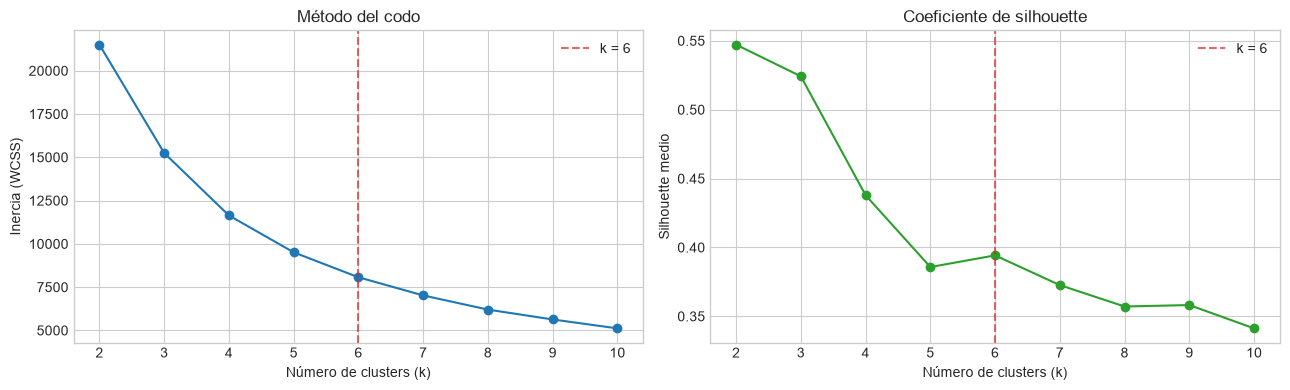

In [3]:
ks = range(2, 11)
inertias, silhouettes = [], []

# El silhouette es O(n²): lo calculamos sobre una muestra de 5.000 puntos.
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_train_scaled), size=5_000, replace=False)

for k in ks:
    candidate = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    candidate.fit(X_train_scaled)
    inertias.append(candidate.inertia_)
    silhouettes.append(
        silhouette_score(X_train_scaled[sample_idx], candidate.labels_[sample_idx])
    )

display(pd.DataFrame({"k": list(ks), "inercia": inertias, "silhouette": silhouettes}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(ks), inertias, marker="o", color="tab:blue")
axes[0].axvline(6, color="tab:red", linestyle="--", alpha=0.7, label="k = 6")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia (WCSS)")
axes[0].legend()

axes[1].plot(list(ks), silhouettes, marker="o", color="tab:green")
axes[1].axvline(6, color="tab:red", linestyle="--", alpha=0.7, label="k = 6")
axes[1].set_title("Coeficiente de silhouette")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette medio")
axes[1].legend()

plt.tight_layout()
plt.show()

Ajustamos el modelo definitivo con `k = 6` sobre el train escalado. K-Means devuelve etiquetas enteras (`0`–`5`); las convertimos a tipo `category` para que pandas las trate como grupo y no como una magnitud numérica. La columna se llama `cluster`, como pide el enunciado.

In [4]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_train_scaled)

train["cluster"] = pd.Categorical(kmeans.predict(X_train_scaled))

print(f"dtype de la columna cluster: {train['cluster'].dtype}")
print(f"Valores únicos: {sorted(train['cluster'].cat.categories.tolist())}")
display(train["cluster"].value_counts().sort_index().to_frame("n"))

dtype de la columna cluster: category
Valores únicos: [0, 1, 2, 3, 4, 5]


,n
cluster,
0,1321
1,3380
2,453
3,3931
4,2239
5,5188


Para interpretar los grupos calculamos el perfil de cada cluster: cuántas casas contiene, su renta media y su centro geográfico. Los centroides se devuelven a unidades originales (grados y decenas de miles de dólares) invirtiendo el escalado.

In [5]:
# Centroides en unidades originales.
centroids = scaler.inverse_transform(kmeans.cluster_centers_)

profiles = (
    train.groupby("cluster", observed=True)
    .agg(
        n=("MedInc", "size"),
        medinc_mean=("MedInc", "mean"),
        medinc_median=("MedInc", "median"),
        latitude_mean=("Latitude", "mean"),
        longitude_mean=("Longitude", "mean"),
    )
    .assign(
        share_pct=lambda x: 100 * x["n"] / len(train),
        centroid_latitude=centroids[:, 0],
        centroid_longitude=centroids[:, 1],
    )
)
display(profiles.round(2))

print(f"Inercia train: {kmeans.inertia_:,.1f}")
print(
    "Silhouette train (muestra): "
    f"{silhouette_score(X_train_scaled[sample_idx], kmeans.labels_[sample_idx]):.3f}"
)

,n,medinc_mean,medinc_median,latitude_mean,longitude_mean,share_pct,centroid_latitude,centroid_longitude
cluster,,,,,,,,
0,1321,2.63,2.56,36.08,-119.73,8.00,36.08,-119.73
1,3380,5.31,5.10,33.87,-118.02,20.47,33.87,-118.02
2,453,10.44,10.12,34.90,-119.24,2.74,34.89,-119.23
3,3931,2.84,2.89,38.35,-121.90,23.81,38.35,-121.90
4,2239,5.52,5.22,37.70,-121.94,13.56,37.70,-121.94
5,5188,2.78,2.85,33.82,-117.82,31.42,33.82,-117.82


Inercia train: 8,069.2


Silhouette train (muestra): 0.394


El gráfico de puntos es la vista principal del clustering: longitud en el eje X, latitud en el eje Y y color por cluster. Los centroides aparecen como cruces negras. A la derecha, la distribución de `MedInc` por cluster para ver qué grupos son más caros.

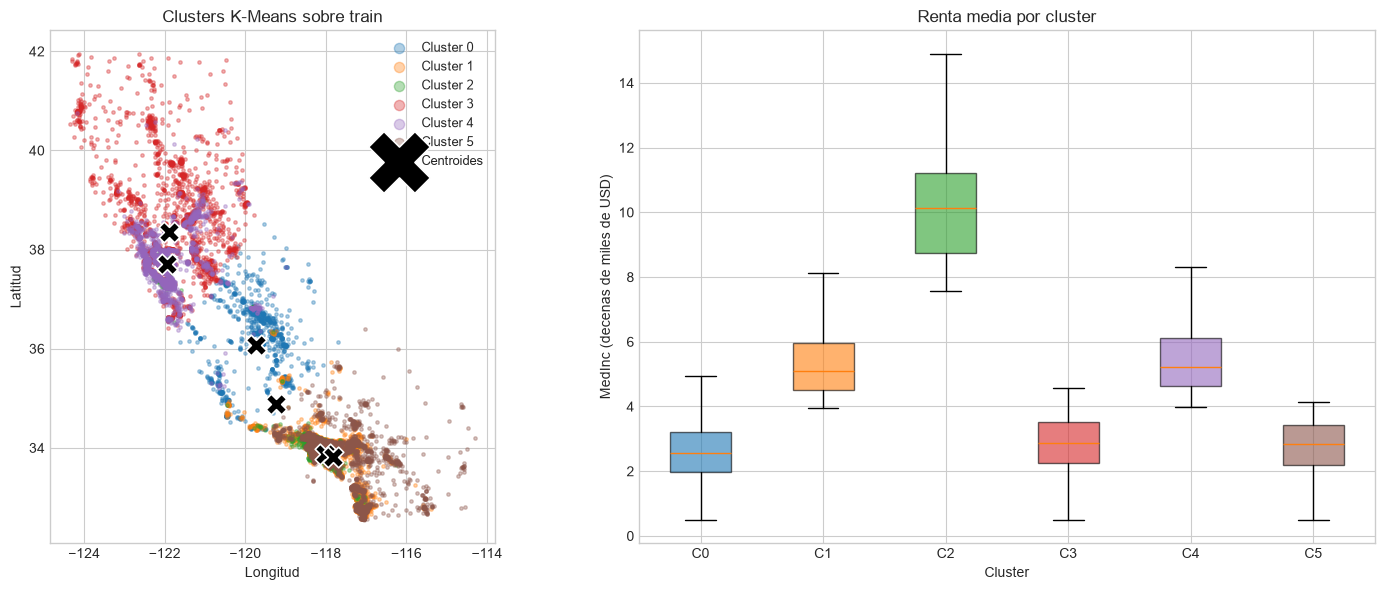

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for cluster_id in range(N_CLUSTERS):
    subset = train[train["cluster"] == cluster_id]
    axes[0].scatter(
        subset["Longitude"],
        subset["Latitude"],
        s=6,
        alpha=0.35,
        color=f"C{cluster_id}",
        label=f"Cluster {cluster_id}",
    )

axes[0].scatter(
    centroids[:, 1],
    centroids[:, 0],
    marker="X",
    s=220,
    c="black",
    edgecolors="white",
    linewidths=1.2,
    zorder=5,
    label="Centroides",
)
axes[0].set_title("Clusters K-Means sobre train")
axes[0].set_xlabel("Longitud")
axes[0].set_ylabel("Latitud")
axes[0].legend(markerscale=3, fontsize=9, loc="upper right")
axes[0].set_aspect(1 / np.cos(np.deg2rad(train["Latitude"].mean())))

income_by_cluster = [
    train.loc[train["cluster"] == cluster_id, "MedInc"] for cluster_id in range(N_CLUSTERS)
]
box = axes[1].boxplot(
    income_by_cluster,
    tick_labels=[f"C{i}" for i in range(N_CLUSTERS)],
    patch_artist=True,
    showfliers=False,
)
for patch, cluster_id in zip(box["boxes"], range(N_CLUSTERS)):
    patch.set_facecolor(f"C{cluster_id}")
    patch.set_alpha(0.6)
axes[1].set_title("Renta media por cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("MedInc (decenas de miles de USD)")

plt.tight_layout()
plt.show()

### Qué vemos

Los seis grupos combinan geografía y renta. Estos son sus perfiles sobre el train:

| Cluster | % train | MedInc medio | Centro (lat, lon) | Zona aproximada |
| :-----: | :-----: | :----------: | :---------------: | --------------- |
| 0 | 8,0 % | 2,6 | 36,08, −119,73 | Valle Central (Fresno–Bakersfield) |
| 1 | 20,5 % | 5,3 | 33,87, −118,02 | Los Ángeles, Orange County y San Diego |
| 2 | 2,7 % | 10,4 | 34,89, −119,23 | Enclaves de renta alta en todo el estado |
| 3 | 23,8 % | 2,8 | 38,35, −121,90 | Sacramento, norte y costa |
| 4 | 13,6 % | 5,5 | 37,70, −121,94 | Bahía de San Francisco y norte |
| 5 | 31,4 % | 2,8 | 33,82, −117,82 | Inland Empire y sur metropolitano |

- **Geografía:** el scatter separa con claridad el sur (C1/C5), el valle central (C0), Sacramento y el norte (C3) y la bahía de San Francisco (C4). Las concentraciones urbanas se reconocen a simple vista.
- **Renta:** dentro de una misma zona, el cluster separa barrios caros y modestos. C1 (LA/Orange/San Diego, 5,3) y C5 (Inland Empire, 2,8) ocupan prácticamente el mismo territorio y se diferencian por renta. Lo mismo ocurre con C4 (bahía, 5,5) y C3 (norte, 2,8).
- **El caso de C2 es el más interesante.** Es el grupo más caro (MedInc medio 10,4, hasta 15) y el más pequeño (2,7 %). Sus puntos **no forman una región contigua**: aparecen en Malibú, Beverly Hills, la bahía de San Francisco y la costa de San Diego. Al escalar, las rentas extremas quedan muy lejos del resto en el eje de `MedInc` (z ≈ 3–6) y más cerca entre sí que de sus vecinos geográficos con rentas bajas. Es el efecto de dar el mismo peso a las tres variables: la renta extrema “vence” a la distancia geográfica.
- La caja de `MedInc` muestra esa jerarquía: C2 muy por encima, C1 y C4 en una banda media-alta, y C0/C3/C5 concentrados por debajo de 4 (40.000 USD).
- El silhouette de ≈ 0,39 no es alto: hay solapamiento en las fronteras, sobre todo entre clusters que comparten territorio y solo se separan por renta. Es coherente con lo que se ve en el mapa.

**Sobre el codo y el silhouette:** la inercia baja de forma monotónica al añadir clusters; el silhouette es máximo con k = 2 (0,55) y después desciende, con un pequeño repunte en k = 6 (0,394) frente a k = 5 (0,386). Mantenemos **k = 6** porque lo fija el enunciado y porque produce una segmentación interpretable; el silhouette confirma que los grupos no están perfectamente separados.

## Paso 3 — Predicción con el conjunto de test

Ahora asignamos los puntos de test con `kmeans.predict`. Cada punto va al centroide más cercano en el espacio escalado. El test no participó en el ajuste, así que esta asignación es una predicción real sobre datos nuevos.

Comparamos la distribución de clusters entre train y test y calculamos el silhouette del test. Si el modelo generaliza, ambas distribuciones deben parecerse y el silhouette no debe desplomarse.

In [7]:
test_labels = kmeans.predict(X_test_scaled)
test["cluster"] = pd.Categorical(
    test_labels, categories=train["cluster"].cat.categories
)

distribution = pd.DataFrame(
    {
        "train_pct": train["cluster"].value_counts(normalize=True).sort_index().mul(100),
        "test_pct": test["cluster"].value_counts(normalize=True).sort_index().mul(100),
    }
).round(2)
distribution["diff_pp"] = (distribution["test_pct"] - distribution["train_pct"]).round(2)
display(distribution)

squared_distances = ((X_test_scaled - kmeans.cluster_centers_[test_labels]) ** 2).sum(axis=1)
print(
    "Silhouette test: "
    f"{silhouette_score(X_test_scaled, test_labels):.3f}"
)
print(f"Inercia test: {squared_distances.sum():,.1f}")
print(f"Distancia media al centroide: {np.sqrt(squared_distances).mean():.3f}")

,train_pct,test_pct,diff_pp
cluster,,,
0,8.00,8.16,0.16
1,20.47,20.08,-0.39
2,2.74,2.71,-0.03
3,23.81,23.30,-0.51
4,13.56,12.45,-1.11
5,31.42,33.28,1.86


Silhouette test: 0.399
Inercia test: 1,940.0
Distancia media al centroide: 0.602


Superponemos los puntos de test (cruces) sobre el mapa de train (puntos claros). Si la predicción es correcta, cada cruz debe caer dentro de la nube del color que le corresponde.

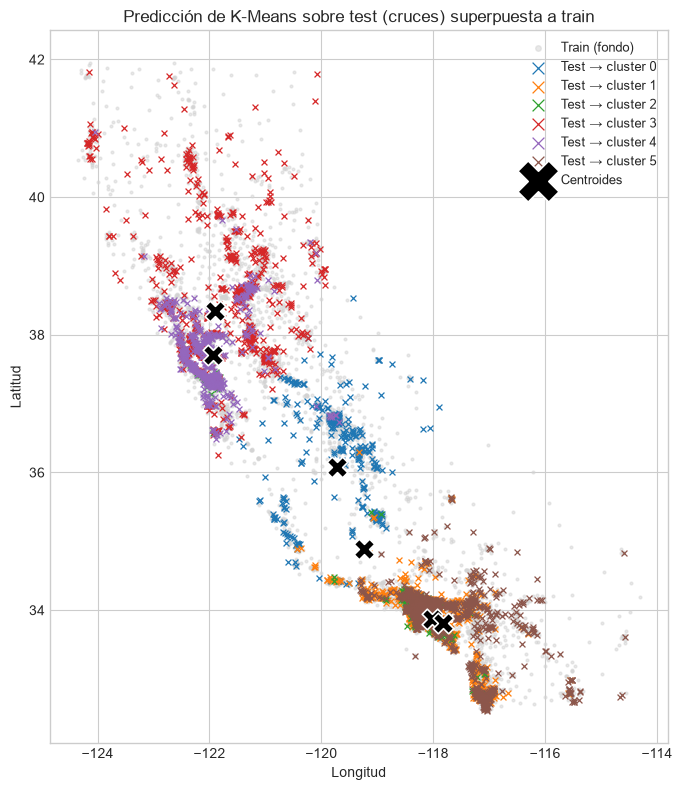

In [8]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    train["Longitude"],
    train["Latitude"],
    s=4,
    c="lightgray",
    alpha=0.5,
    label="Train (fondo)",
)

for cluster_id in range(N_CLUSTERS):
    subset = test[test["cluster"] == cluster_id]
    ax.scatter(
        subset["Longitude"],
        subset["Latitude"],
        s=18,
        marker="x",
        linewidths=0.9,
        color=f"C{cluster_id}",
        label=f"Test → cluster {cluster_id}",
    )

ax.scatter(
    centroids[:, 1],
    centroids[:, 0],
    marker="X",
    s=220,
    c="black",
    edgecolors="white",
    linewidths=1.2,
    zorder=5,
    label="Centroides",
)
ax.set_title("Predicción de K-Means sobre test (cruces) superpuesta a train")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect(1 / np.cos(np.deg2rad(train["Latitude"].mean())))
ax.legend(markerscale=2, fontsize=9, loc="upper right")
plt.tight_layout()
plt.show()

### Interpretación

- Las cruces se distribuyen **dentro de las mismas nubes de color** que el train: el modelo reproduce la geometría aprendida y no inventa regiones nuevas.
- La distribución por cluster es casi idéntica: la mayor diferencia es C5 (+1,9 pp) y C4 (−1,1 pp); el resto queda por debajo de 0,6 pp. El split aleatorio es representativo del conjunto completo.
- El **silhouette de test es 0,399**, prácticamente igual que el de train (0,394), y la distancia media al centroide es 0,60 en unidades escaladas. El modelo generaliza como en entrenamiento.
- Las cruces que caen cerca del borde entre dos nubes son ambiguas por definición: K-Means asigna por distancia y un pequeño cambio de coordenadas o de renta puede mover la etiqueta. Es el mismo tipo de error que cometerá cualquier clasificador supervisado en esa frontera.

## Paso 4 — Modelo de clasificación supervisada

Ya tenemos una etiqueta (`cluster`) para cada casa. El problema supervisado es: **dado `Latitude`, `Longitude` y `MedInc`, predecir el cluster**.

Comparamos tres modelos con validación cruzada estratificada de 5 folds:

- **Logistic Regression**: fronteras lineales. Como los clusters de K-Means son celdas de Voronoi (fronteras lineales en el espacio escalado), es un candidato natural.
- **Random Forest**: captura fronteras no lineales y es robusto sin ajuste fino.
- **K-Nearest Neighbors**: aproxima directamente la noción de cercanía de K-Means.

Todos van dentro de un `Pipeline` con su propio `StandardScaler` para que el preprocesado viaje con el modelo.

In [9]:
# Para los clasificadores partimos de las features SIN escalar:
# cada Pipeline aplica su propio StandardScaler.
X_train_df, X_test_df = train[FEATURES], test[FEATURES]
y_train = train["cluster"].astype(int)
y_test = test["cluster"].astype(int)

candidates = {
    "LogisticRegression": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1_000, random_state=RANDOM_STATE)),
        ]
    ),
    "RandomForest": Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
                ),
            ),
        ]
    ),
    "KNeighbors": Pipeline(
        [
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=15)),
        ]
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, pipeline in candidates.items():
    scores = cross_val_score(
        pipeline, X_train_df, y_train, cv=cv, scoring="accuracy", n_jobs=-1
    )
    cv_results[name] = {"accuracy_media": scores.mean(), "accuracy_std": scores.std()}
    print(f"{name:<20} accuracy CV = {scores.mean():.4f} ± {scores.std():.4f}")

cv_table = pd.DataFrame(cv_results).T.sort_values("accuracy_media", ascending=False)
display(cv_table.round(4))

best_name = cv_table.index[0]
print(f"Modelo seleccionado: {best_name}")

LogisticRegression   accuracy CV = 0.9901 ± 0.0018


RandomForest         accuracy CV = 0.9939 ± 0.0008


KNeighbors           accuracy CV = 0.9882 ± 0.0020


,accuracy_media,accuracy_std
RandomForest,0.9939,0.0008
LogisticRegression,0.9901,0.0018
KNeighbors,0.9882,0.0020


Modelo seleccionado: RandomForest


In [10]:
best_model = candidates[best_name].fit(X_train_df, y_train)
y_pred = best_model.predict(X_test_df)
y_pred_train = best_model.predict(X_train_df)

print(f"Accuracy train: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Accuracy test:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy test: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"F1 macro test: {f1_score(y_test, y_pred, average='macro'):.4f}")

report = pd.DataFrame(
    classification_report(y_test, y_pred, output_dict=True, zero_division=0)
).T
display(report.round(3))

Accuracy train: 1.0000
Accuracy test:  0.9956
Balanced accuracy test: 0.9923
F1 macro test: 0.9940


,precision,recall,f1-score,support
0,0.997,0.985,0.991,337.000
1,0.995,0.998,0.996,829.000
2,1.000,0.982,0.991,112.000
3,0.995,0.994,0.994,962.000
4,0.988,0.996,0.992,514.000
5,0.999,0.999,0.999,1374.000
accuracy,0.996,0.996,0.996,0.996
macro avg,0.996,0.992,0.994,4128.000
weighted avg,0.996,0.996,0.996,4128.000


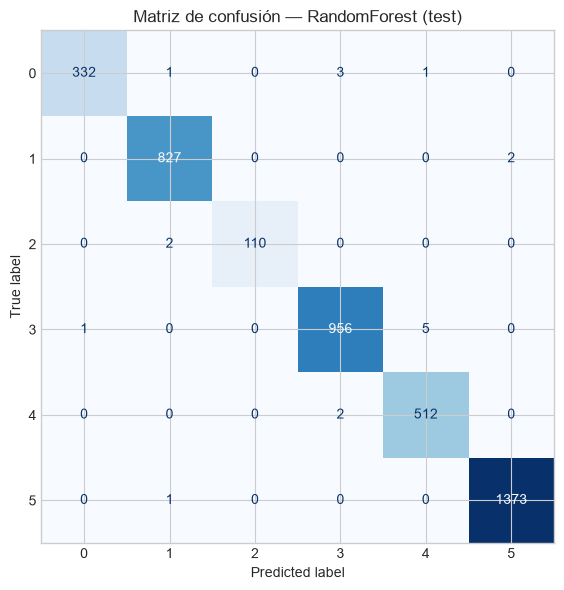

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"Matriz de confusión — {best_name} (test)")
plt.tight_layout()
plt.show()

### Lectura de las métricas

- **Random Forest gana la validación cruzada**: 0,9939 ± 0,0008 frente a 0,9901 de Logistic Regression y 0,9882 de KNN. La diferencia es pequeña, pero consistente en los cinco folds.
- En test, el modelo elegido obtiene **accuracy 0,9956**, **balanced accuracy 0,9923** y **F1 macro 0,9940**. Solo falla **18 de 4.128 puntos (0,44 %)**.
- La accuracy de train es 1,0000: el bosque memoriza el train, pero la caída en test es de solo 0,44 pp, así que no hay un sobreajuste preocupante.
- La matriz de confusión se concentra en la diagonal. Los errores aparecen entre clusters **vecinos o solapados**: C0 ↔ C3 (valle central y norte), C3 ↔ C4 (norte y bahía), C1 ↔ C5 (LA/Orange y Inland Empire) y C2 → C1. Nunca se confunden clusters alejados del mapa.
- El clasificador reproduce casi a la perfección las etiquetas del K-Means. Es lo esperado: las etiquetas se calcularon con las **mismas tres features** y K-Means define fronteras geométricas simples. Un accuracy muy alto aquí **no demuestra capacidad predictiva sobre una variable externa**; demuestra que el modelo aprendió fielmente la partición.
- **¿Para qué sirve entonces el clasificador?** Para asignar el cluster a puntos nuevos con un artefacto más ligero y rápido que cargar K-Means, y para poder sustituir después K-Means por etiquetas humanas o de negocio sin cambiar la interfaz de predicción.

## Paso 5 — Guardado de los modelos

Guardamos dos pipelines **autocontenidos** en `models/`:

- `kmeans_housing.joblib`: `StandardScaler` + `KMeans`.
- `classifier_housing.joblib`: `StandardScaler` + clasificador elegido.

También guardamos `metadata.json` con features, hiperparámetros, métricas, perfiles de cluster y versiones, y el dataset etiquetado en `data/processed/housing_clusters.csv`.

In [12]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)

# Pipeline de K-Means con los pasos ya ajustados.
kmeans_pipeline = Pipeline([("scaler", scaler), ("kmeans", kmeans)])
joblib.dump(kmeans_pipeline, MODELS_DIR / "kmeans_housing.joblib")
joblib.dump(best_model, MODELS_DIR / "classifier_housing.joblib")

# Dataset etiquetado: train y test en un solo CSV con la columna split.
labeled = df.copy()
labeled["split"] = "train"
labeled.loc[test_index, "split"] = "test"
labeled["cluster"] = pd.NA
labeled.loc[train_index, "cluster"] = kmeans.predict(X_train_scaled)
labeled.loc[test_index, "cluster"] = test_labels
labeled["cluster"] = labeled["cluster"].astype(int).astype("category")
labeled.to_csv(PROCESSED_PATH, index=True, index_label="row_id")

metadata = {
    "project": "California Housing K-Means",
    "features": FEATURES,
    "n_clusters": N_CLUSTERS,
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "kmeans": {
        "params": {"n_clusters": N_CLUSTERS, "n_init": 10, "random_state": RANDOM_STATE},
        "inertia_train": float(kmeans.inertia_),
        "silhouette_test": float(silhouette_score(X_test_scaled, test_labels)),
    },
    "classifier": {
        "selected": best_name,
        "cv_accuracy": {
            name: {
                "mean": float(values["accuracy_media"]),
                "std": float(values["accuracy_std"]),
            }
            for name, values in cv_results.items()
        },
        "test_accuracy": float(accuracy_score(y_test, y_pred)),
        "test_balanced_accuracy": float(balanced_accuracy_score(y_test, y_pred)),
        "test_f1_macro": float(f1_score(y_test, y_pred, average="macro")),
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
    },
    "cluster_profiles": profiles.reset_index().round(3).to_dict(orient="records"),
    "versions": {
        "scikit-learn": __import__("sklearn").__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "joblib": joblib.__version__,
    },
}
(MODELS_DIR / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Artefactos escritos:")
for path in [
    MODELS_DIR / "kmeans_housing.joblib",
    MODELS_DIR / "classifier_housing.joblib",
    MODELS_DIR / "metadata.json",
    PROCESSED_PATH,
]:
    print(f"  {path.relative_to(ROOT)}")

Artefactos escritos:
  models/kmeans_housing.joblib
  models/classifier_housing.joblib
  models/metadata.json
  data/processed/housing_clusters.csv


Verificamos que los artefactos guardados se pueden recargar y que producen exactamente las mismas predicciones. Es la comprobación mínima antes de dar un modelo por entregado.

In [13]:
loaded_kmeans = joblib.load(MODELS_DIR / "kmeans_housing.joblib")
loaded_classifier = joblib.load(MODELS_DIR / "classifier_housing.joblib")

kmeans_reloaded = loaded_kmeans.predict(test[FEATURES])
classifier_reloaded = loaded_classifier.predict(test[FEATURES])

print("K-Means recargado coincide:", np.array_equal(kmeans_reloaded, test_labels))
print("Clasificador recargado coincide:", np.array_equal(classifier_reloaded, y_pred))

assert np.array_equal(kmeans_reloaded, test_labels)
assert np.array_equal(classifier_reloaded, y_pred)
print("Verificación correcta: los .joblib reproducen las predicciones originales.")

K-Means recargado coincide: True
Clasificador recargado coincide: True
Verificación correcta: los .joblib reproducen las predicciones originales.


## Conclusiones

- **K-Means encuentra estructura real combinando región y renta.** Con solo latitud, longitud y renta, los 6 clusters separan el sur metropolitano (C1/C5), el valle central (C0), Sacramento y el norte (C3) y la bahía de San Francisco (C4), y dentro de cada zona distinguen barrios caros y modestos.
- **El cluster 2 es un hallazgo, no un error.** Agrupa los enclaves de renta alta de todo el estado (Malibú, Beverly Hills, bahía de San Francisco, costa de San Diego). Al escalar, las rentas extremas pesan mucho en la distancia y esos puntos quedan más cerca entre sí que de sus vecinos geográficos pobres.
- **Escalar no es opcional.** Sin `StandardScaler`, `MedInc` queda aplastada por las coordenadas y el clustering se convierte en un simple mapa. Con escalado, las tres variables contribuyen, aunque eso produce el efecto de C2.
- **El test confirma la asignación.** Las distribuciones train/test difieren menos de 2 pp, el silhouette se mantiene en 0,399 y las cruces caen dentro de las nubes correspondientes. Las únicas dudas están en las fronteras entre clusters vecinos.
- **El clasificador supervisado es un “compilador” de las etiquetas de K-Means.** Random Forest alcanza accuracy 0,9956 y F1 macro 0,9940 en test, con solo 18 errores. Su valor práctico es la velocidad y la posibilidad de reutilizar la interfaz con etiquetas futuras; no es evidencia de que el cluster sea un objetivo de negocio externo.
- **Limitación honesta:** los clusters son una fotografía del censo de 1990 y de tres variables. No incorporan precio de la vivienda (`MedHouseVal`), tamaño de la casa ni datos actuales, así que describen segmentos, no predicen precio.